# Lab 4 — Assignment


**Based on:** Lab-4-b (Bernoulli, Binomial, Poisson, Normal, Uniform)


---

### Instructions

1. Run the **Setup** cell first. Do not modify it.
2. There are **10 questions** — two on each distribution. Attempt **all** of them.
3. Every question has three parts:
   - **(a)** and **(b)** — work these out **by hand** and type your working in the *Written answer* cell.
   - **(c)** — write **Python code** in the blank code cell provided and produce the plot asked for.
4. Use `DISCRETE_COLOR` for discrete plots (bars) and `CONTINUOUS_COLOR` for continuous plots (curves).
5. Every plot must have an **x-label, y-label and a title**. Marks are deducted for unlabelled plots.
6. Round all probabilities to **4 decimal places**.
7. Save the notebook with all outputs visible before submitting.

### Marks distribution

| Section | Questions | Marks each | Total |
|---|---|---|---|
| A — Bernoulli | Q1, Q2 | 5 | 10 |
| B — Binomial | Q3, Q4 | 5 | 10 |
| C — Poisson | Q5, Q6 | 5 | 10 |
| D — Normal | Q7, Q8 | 5 | 10 |
| E — Uniform | Q9, Q10 | 5 | 10 |
| | | **Total** | **50** |

### Quick reference — which function do I need?

| Task | `scipy.stats` call |
|---|---|
| $P(X = k)$, discrete | `.pmf(k, ...)` |
| $f(x)$, continuous | `.pdf(x, ...)` |
| $P(X \le x)$ | `.cdf(x, ...)` |
| $P(X > x)$ | `.sf(x, ...)` |
| Value with given $P(X \le x)$ | `.ppf(prob, ...)` |
| Mean / variance | `.mean(...)`, `.var(...)` |
| Random samples | `.rvs(..., size=n, random_state=seed)` |

---

## Setup
Run this cell first — do not change it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from math import comb, factorial, exp, sqrt

DISCRETE_COLOR = "#0E9F9A"     # teal   -> discrete distributions
CONTINUOUS_COLOR = "#E4572E"   # orange -> continuous distributions
HIGHLIGHT_COLOR = "#F4A261"    # use this to highlight a bar or a shaded area

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Setup complete — you are ready to start.")

Setup complete — you are ready to start.


---
# Part A — Bernoulli distribution
*Recall:* $P(X=x) = p^x(1-p)^{1-x}$ for $x \in \{0,1\}$, $\;E[X]=p$, $\;Var(X)=p(1-p)$.

## Q1. The library gate scanner 

> 📚 The RFID gate at the college library reads a student's ID card correctly on the **first tap 92%** of the time. One student taps her card once.
>
> Let $X = 1$ if the card is read on the first tap, and $X = 0$ if it is not.
>
> **(a)** State the value of $p$ and find $P(X=1)$ and $P(X=0)$.
> **(b)** Find the mean and the variance of $X$, showing the substitution into the formulas.
> **(c)** Write Python code that:
> - builds the PMF of $X$ using `stats.bernoulli.pmf`,
> - draws a **bar chart** of the distribution in `DISCRETE_COLOR` with the ticks labelled `"Not read (0)"` and `"Read (1)"`,
> - writes the probability value on top of each bar,
> - prints the mean and the variance obtained from `scipy`, and checks that they match your hand answers in (b).

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

**(a)** The success probability is $p = 0.92$ (card read on first tap).

$$P(X=1) = p^1(1-p)^0 = 0.92 \qquad P(X=0) = p^0(1-p)^1 = 1-0.92 = 0.08$$

**(b)**
$$E[X] = p = 0.92$$
$$Var(X) = p(1-p) = 0.92 \times 0.08 = 0.0736$$


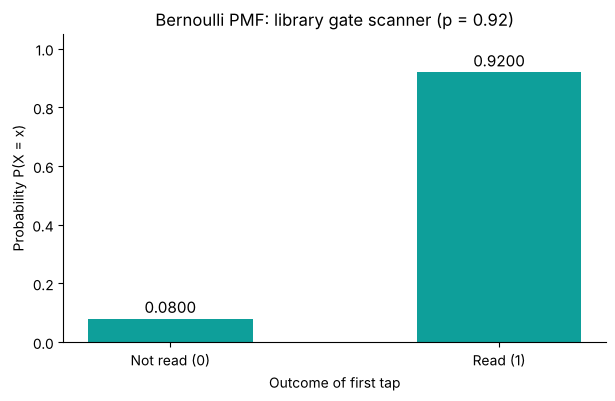

scipy mean     = 0.9200   hand answer = 0.9200
scipy variance = 0.0736   hand answer = 0.0736
Match with hand answers: True


In [2]:
p = 0.92
x = np.array([0, 1])
pmf = stats.bernoulli.pmf(x, p)

fig, ax = plt.subplots()
ax.bar(x, pmf, color=DISCRETE_COLOR, width=0.5)
for xi, pi in zip(x, pmf):
    ax.text(xi, pi + 0.02, f"{pi:.4f}", ha="center", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(["Not read (0)", "Read (1)"])
ax.set_ylim(0, 1.05)
ax.set_xlabel("Outcome of first tap")
ax.set_ylabel("Probability P(X = x)")
ax.set_title("Bernoulli PMF: library gate scanner (p = 0.92)")
plt.show()

mean_s, var_s = stats.bernoulli.mean(p), stats.bernoulli.var(p)
print(f"scipy mean     = {mean_s:.4f}   hand answer = {p:.4f}")
print(f"scipy variance = {var_s:.4f}   hand answer = {p*(1-p):.4f}")
print("Match with hand answers:", np.isclose(mean_s, p) and np.isclose(var_s, p*(1-p)))

## Q2. Estimating $p$ from attendance data &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> 👆 A biometric attendance device records whether a student's fingerprint is accepted on the **first attempt**. Over one semester the device logged **2,000 scans**, of which **1,740** were accepted on the first attempt. Treat one scan as a single Bernoulli trial with $X=1$ for *accepted*.
>
> **(a)** Estimate $p$ from the data and write down the full PMF $P(X=x)$ with the estimated value substituted in.
> **(b)** Find the mean and variance. Then answer: for what value of $p$ would the variance of a Bernoulli variable be the **largest possible**, and what is that largest value? Justify your answer using the formula $Var(X)=p(1-p)$.
> **(c)** Write Python code that:
> - simulates 2,000 Bernoulli trials with your estimated $p$ using `stats.bernoulli.rvs(..., random_state=42)`,
> - prints the **simulated proportion** of successes next to the theoretical $p$,
> - plots the **theoretical PMF and the simulated relative frequencies side by side** as grouped bars with a legend,
> - plots $Var(X)=p(1-p)$ against $p$ for $p$ from 0 to 1 in a **second figure**, and marks the maximum point with a marker and an annotation.

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

**(a)** Estimate of $p$ = proportion accepted = $\dfrac{1740}{2000} = 0.87$.

$$P(X=x) = (0.87)^x(0.13)^{1-x},\quad x\in\{0,1\}$$
i.e. $P(X=1)=0.87$ and $P(X=0)=0.13$.

**(b)**
$$E[X] = p = 0.87$$
$$Var(X) = p(1-p) = 0.87 \times 0.13 = 0.1131$$

*Largest possible variance:* write $Var(X) = p - p^2$. Differentiating, $\dfrac{d}{dp}(p-p^2) = 1 - 2p = 0 \Rightarrow p = 0.5$, and the second derivative is $-2 < 0$, so this is a maximum. (Equivalently, $p(1-p) = \tfrac14 - (p-\tfrac12)^2 \le \tfrac14$.)

$$Var_{max} = 0.5 \times 0.5 = 0.25 \quad\text{at } p = 0.5$$

Intuition: at $p=0.5$ the outcome is the most uncertain; as $p \to 0$ or $1$ the outcome becomes almost certain and the variance shrinks to 0.


Theoretical p        = 0.8700
Simulated proportion = 0.8675


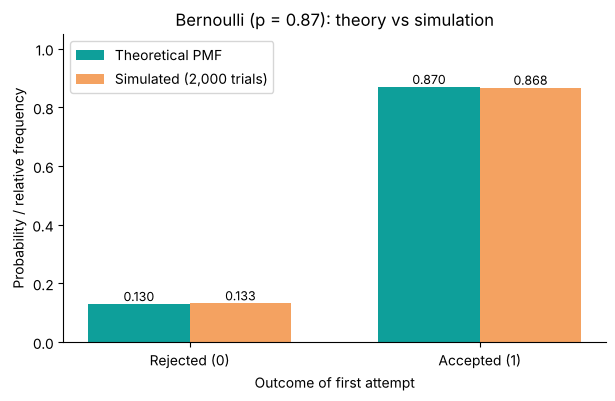

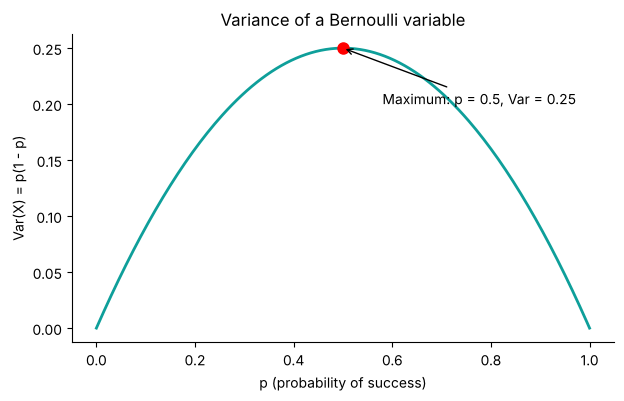

In [3]:
p_hat = 1740 / 2000
n = 2000
sim = stats.bernoulli.rvs(p_hat, size=n, random_state=42)

print(f"Theoretical p        = {p_hat:.4f}")
print(f"Simulated proportion = {sim.mean():.4f}")

# Figure 1: theoretical PMF vs simulated relative frequencies (grouped bars)
x = np.array([0, 1])
theo = stats.bernoulli.pmf(x, p_hat)
simf = np.array([(sim == 0).mean(), (sim == 1).mean()])
w = 0.35
fig, ax = plt.subplots()
ax.bar(x - w/2, theo, w, color=DISCRETE_COLOR, label="Theoretical PMF")
ax.bar(x + w/2, simf, w, color=HIGHLIGHT_COLOR, label="Simulated (2,000 trials)")
for xi, a, b in zip(x, theo, simf):
    ax.text(xi - w/2, a + 0.01, f"{a:.3f}", ha="center", fontsize=9)
    ax.text(xi + w/2, b + 0.01, f"{b:.3f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(["Rejected (0)", "Accepted (1)"])
ax.set_ylim(0, 1.05)
ax.set_xlabel("Outcome of first attempt")
ax.set_ylabel("Probability / relative frequency")
ax.set_title("Bernoulli (p = 0.87): theory vs simulation")
ax.legend()
plt.show()

# Figure 2: Var(X) = p(1-p)
pp = np.linspace(0, 1, 201)
fig, ax = plt.subplots()
ax.plot(pp, pp * (1 - pp), color=DISCRETE_COLOR, lw=2)
ax.plot(0.5, 0.25, "o", color="red", markersize=8)
ax.annotate("Maximum: p = 0.5, Var = 0.25", xy=(0.5, 0.25), xytext=(0.58, 0.20),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("p (probability of success)")
ax.set_ylabel("Var(X) = p(1 - p)")
ax.set_title("Variance of a Bernoulli variable")
plt.show()

---
# Part B — Binomial distribution
*Recall:* $P(X=k) = \binom{n}{k}p^k(1-p)^{n-k}$, $\;E[X]=np$, $\;Var(X)=np(1-p)$.

## Q3. Guessing a multiple-choice quiz &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 📝 An online quiz has **12 multiple-choice questions**, each with **4 options** and exactly one correct answer. A student who has not studied guesses every answer at random. Let $X$ = number of questions answered correctly.
>
> **(a)** State $n$ and $p$, check that the **BINS** conditions hold, and compute $P(X=5)$ **by hand**, showing the value of $\binom{12}{5}$.
> **(b)** Find the mean and the variance of $X$.
> **(c)** Write Python code that:
> - plots the PMF as a bar chart for $k = 0$ to $12$ in `DISCRETE_COLOR`,
>

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

**(a)** $n = 12$, $p = \dfrac14 = 0.25$.

BINS check: **B**inary – each answer is correct/incorrect; **I**ndependent – one random guess doesn't affect another; **N**umber of trials fixed at 12; **S**ame $p=0.25$ for every question. So $X \sim Bin(12, 0.25)$.

$$\binom{12}{5} = \frac{12!}{5!\,7!} = 792$$
$$P(X=5) = 792 \times (0.25)^5 \times (0.75)^7 = 792 \times 0.000977 \times 0.1335 \approx 0.1032$$

**(b)**
$$E[X] = np = 12 \times 0.25 = 3$$
$$Var(X) = np(1-p) = 12 \times 0.25 \times 0.75 = 2.25$$


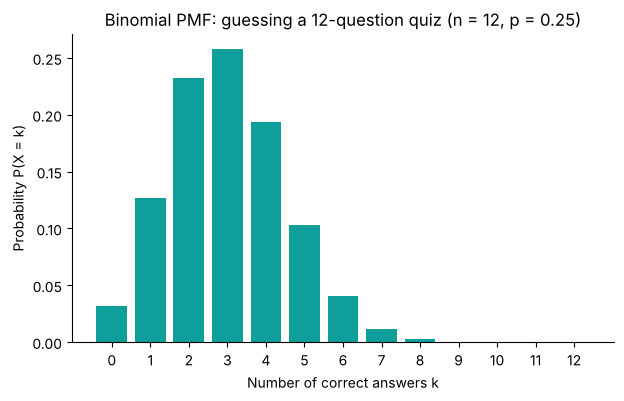

C(12,5)  = 792
P(X = 5) = 0.1032
mean = 3.0000, variance = 2.2500


In [4]:
n, p = 12, 0.25
k = np.arange(0, n + 1)
pmf = stats.binom.pmf(k, n, p)

fig, ax = plt.subplots()
ax.bar(k, pmf, color=DISCRETE_COLOR)
ax.set_xticks(k)
ax.set_xlabel("Number of correct answers k")
ax.set_ylabel("Probability P(X = k)")
ax.set_title("Binomial PMF: guessing a 12-question quiz (n = 12, p = 0.25)")
plt.show()

# check of hand answers
print(f"C(12,5)  = {comb(12, 5)}")
print(f"P(X = 5) = {stats.binom.pmf(5, n, p):.4f}")
print(f"mean = {stats.binom.mean(n, p):.4f}, variance = {stats.binom.var(n, p):.4f}")

#### ✍️ Written answer (a), (b) and (d) — *type your hand calculation below*

*The text of Question 4 is not present in the supplied notebook (the question cell is missing), so there is nothing to answer here. Send me the question text and I will complete it.*


---
# Part C — Poisson distribution
*Recall:* $P(X=k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$, $\;E[X]=Var(X)=\lambda$.

## Q5. Help-desk emails &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 📧 The IT help-desk of a college receives on average **3 emails per hour**. Let $X$ = number of emails received in one hour.
>
> **(a)** Compute $P(X = 0)$ and $P(X = 2)$ **by hand**, showing the substitution into the formula ($e^{-3} \approx 0.0498$).
> **(b)** State the mean and the variance, and explain in one line what is special about them for a Poisson distribution.
> **(c)** Write Python code that:
> - plots the PMF as a bar chart for $k = 0$ to $12$ in `DISCRETE_COLOR`,
> - prints $P(X=0)$, $P(X=2)$ and $P(X \le 5)$,
> - prints the smallest value of $k$ for which $P(X \le k) \ge 0.95$ (use `.ppf` or a loop).

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

**(a)** $\lambda = 3$.

$$P(X=0) = \frac{3^0 e^{-3}}{0!} = e^{-3} \approx 0.0498$$
$$P(X=2) = \frac{3^2 e^{-3}}{2!} = \frac{9 \times 0.0498}{2} \approx 0.2240$$

**(b)** Mean $= \lambda = 3$ and variance $= \lambda = 3$. Special property: for a Poisson distribution the **mean equals the variance**.


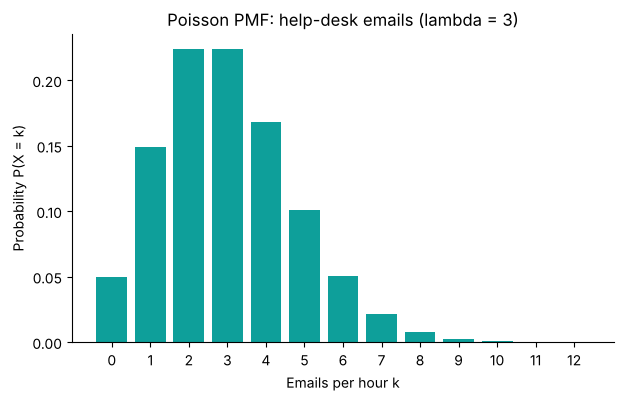

P(X = 0)  = 0.0498
P(X = 2)  = 0.2240
P(X <= 5) = 0.9161
Smallest k with P(X <= k) >= 0.95: k = 6  (P(X <= 6) = 0.9665)


In [5]:
lam = 3
k = np.arange(0, 13)
pmf = stats.poisson.pmf(k, lam)

fig, ax = plt.subplots()
ax.bar(k, pmf, color=DISCRETE_COLOR)
ax.set_xticks(k)
ax.set_xlabel("Emails per hour k")
ax.set_ylabel("Probability P(X = k)")
ax.set_title("Poisson PMF: help-desk emails (lambda = 3)")
plt.show()

print(f"P(X = 0)  = {stats.poisson.pmf(0, lam):.4f}")
print(f"P(X = 2)  = {stats.poisson.pmf(2, lam):.4f}")
print(f"P(X <= 5) = {stats.poisson.cdf(5, lam):.4f}")
k95 = int(stats.poisson.ppf(0.95, lam))
print(f"Smallest k with P(X <= k) >= 0.95: k = {k95}  (P(X <= {k95}) = {stats.poisson.cdf(k95, lam):.4f})")

## Q6. Server errors over a night shift &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> 🖥️ A web server logs errors at an average rate of **1.5 errors per hour**. The night shift runs from 10 pm to 6 am, i.e. **8 hours**.
>
> **(a)** Find the value of $\lambda$ for the **whole 8-hour shift**, and compute by hand the probability of a **clean shift** (zero errors in the 8 hours).
> **(b)** State the mean and variance for the 8-hour window. The on-call engineer is paged if **more than 18 errors** occur in the shift — write the expression for that probability and name the `scipy` function that gives it directly.
> **(c)** Write Python code that:
> - creates **two subplots side by side** — the PMF for the 1-hour window ($\lambda = 1.5$) and the PMF for the 8-hour window — each with its own sensible range of $k$, title and labels,


#### ✍️ Written answer (a), (b) and (d) — *type your hand calculation below*

**(a)** Rate 1.5 per hour over 8 hours: $\lambda = 1.5 \times 8 = 12$.

$$P(X=0) = \frac{12^0 e^{-12}}{0!} = e^{-12} \approx 6.14 \times 10^{-6} \approx 0.0000$$
(a clean shift is practically impossible).

**(b)** Mean $= \lambda = 12$, variance $= \lambda = 12$.

Paging probability:
$$P(X > 18) = 1 - P(X \le 18) = \sum_{k=19}^{\infty}\frac{12^k e^{-12}}{k!}$$
In `scipy` this is given directly by the survival function `stats.poisson.sf(18, 12)`.


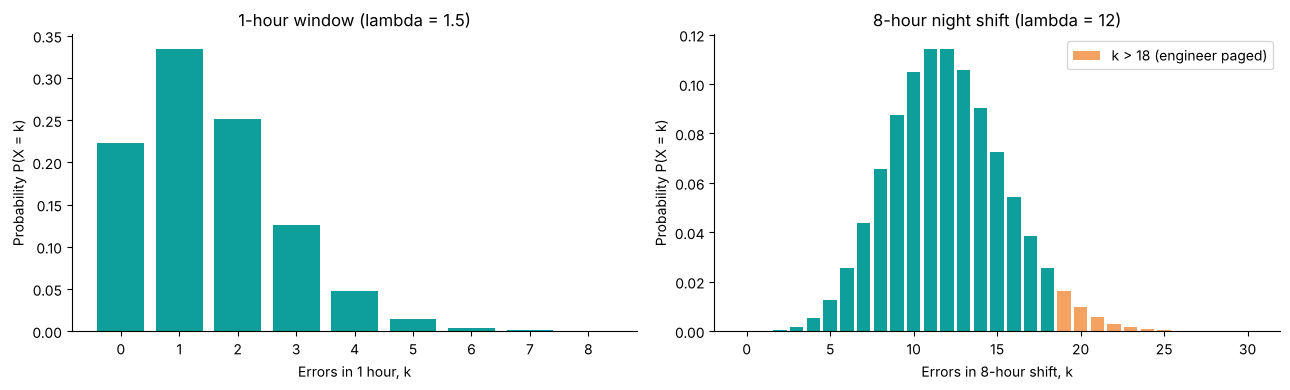

lambda (8 h)        = 12.0
mean = 12.0, variance = 12.0
P(clean shift) P(X=0) = 0.0000  (6.144e-06)
P(X > 18)             = 0.0374


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# 1-hour window
lam1 = 1.5
k1 = np.arange(0, 9)
axes[0].bar(k1, stats.poisson.pmf(k1, lam1), color=DISCRETE_COLOR)
axes[0].set_xticks(k1)
axes[0].set_xlabel("Errors in 1 hour, k")
axes[0].set_ylabel("Probability P(X = k)")
axes[0].set_title("1-hour window (lambda = 1.5)")

# 8-hour window
lam8 = 1.5 * 8
k8 = np.arange(0, 31)
axes[1].bar(k8, stats.poisson.pmf(k8, lam8), color=DISCRETE_COLOR)
axes[1].bar(k8[k8 > 18], stats.poisson.pmf(k8[k8 > 18], lam8), color=HIGHLIGHT_COLOR, label="k > 18 (engineer paged)")
axes[1].set_xlabel("Errors in 8-hour shift, k")
axes[1].set_ylabel("Probability P(X = k)")
axes[1].set_title("8-hour night shift (lambda = 12)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"lambda (8 h)        = {lam8}")
print(f"mean = {stats.poisson.mean(lam8)}, variance = {stats.poisson.var(lam8)}")
print(f"P(clean shift) P(X=0) = {stats.poisson.pmf(0, lam8):.4f}  ({stats.poisson.pmf(0, lam8):.3e})")
print(f"P(X > 18)             = {stats.poisson.sf(18, lam8):.4f}")

---
# Part D — Normal distribution
*Recall:* $f(x)=\dfrac{1}{\sigma\sqrt{2\pi}}e^{-(x-\mu)^2/2\sigma^2}$, $\;Z=\dfrac{X-\mu}{\sigma}$, $\;E[X]=\mu$, $\;Var(X)=\sigma^2$.

## Q7. Battery life of a phone &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 🔋 The battery life of a phone model is normally distributed with a mean of **18 hours** and a standard deviation of **1.5 hours**. Let $X$ = battery life of a randomly chosen phone.
>
> **(a)** Compute the **Z-score** for a battery life of 15 hours and say in words what that Z-score means.
> **(b)** Using the 68–95–99.7 rule, state the interval of battery lives that contains about **95%** of the phones. Show how you obtained it.
> **(c)** Write Python code that:
> - generates 400 equally spaced values of $x$ over $\mu \pm 4\sigma$ and computes the PDF,
> - plots the curve in `CONTINUOUS_COLOR` with a title and axis labels,
.

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

**(a)**
$$Z = \frac{X-\mu}{\sigma} = \frac{15-18}{1.5} = -2$$
A battery life of 15 hours is **2 standard deviations below the mean**, so it is an unusually short battery life.

**(b)** About 95% of values lie within $\mu \pm 2\sigma$:
$$18 \pm 2(1.5) = 18 \pm 3 \;\Rightarrow\; [15,\ 21] \text{ hours}$$
So about 95% of phones have a battery life between 15 and 21 hours.


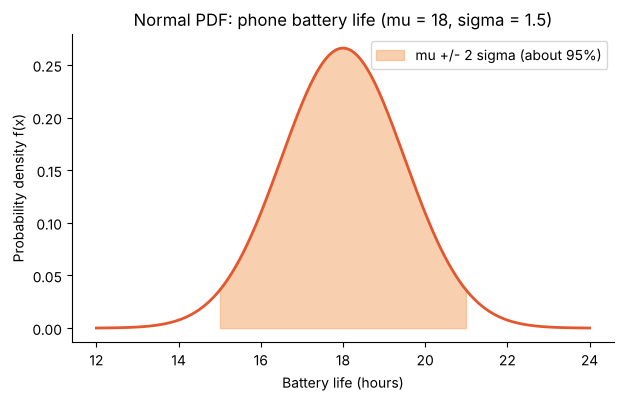

Z for 15 h = -2.0
P(15 <= X <= 21) = 0.9545


In [7]:
mu, sigma = 18, 1.5
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
y = stats.norm.pdf(x, mu, sigma)

fig, ax = plt.subplots()
ax.plot(x, y, color=CONTINUOUS_COLOR, lw=2)
mask = (x >= mu - 2*sigma) & (x <= mu + 2*sigma)
ax.fill_between(x[mask], y[mask], color=HIGHLIGHT_COLOR, alpha=0.5, label="mu +/- 2 sigma (about 95%)")
ax.set_xlabel("Battery life (hours)")
ax.set_ylabel("Probability density f(x)")
ax.set_title("Normal PDF: phone battery life (mu = 18, sigma = 1.5)")
ax.legend()
plt.show()

print(f"Z for 15 h = {(15 - mu) / sigma:.1f}")
print(f"P(15 <= X <= 21) = {stats.norm.cdf(21, mu, sigma) - stats.norm.cdf(15, mu, sigma):.4f}")

## Q8. Calibrating a coffee machine &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> ☕ A vending machine fills cups with coffee. The fill volume is normally distributed with a mean of **200 ml**, but the standard deviation is **not known**. The service log shows that **2.5% of cups overflow**, which happens whenever the fill exceeds **210 ml**.
>
> **(a)** Using the standard normal value $z_{0.975} \approx 1.96$, find the standard deviation $\sigma$ of the fill volume. Show the working.
> **(b)** With that $\sigma$, find the volume below which only **1%** of cups fall (the 1st percentile), and state which `scipy` function gives it. A customer complains if the cup holds less than **190 ml** — write the expression for that probability.
> **(c)** Write Python code that:
> - computes $\sigma$ using `stats.norm.ppf` rather than the rounded 1.96,
> - plots the PDF over a sensible range in `CONTINUOUS_COLOR`,



#### ✍️ Written answer (a), (b) and (d) — *type your hand calculation below*

**(a)** $P(X > 210) = 0.025$, so 210 is the 97.5th percentile: $z_{0.975} \approx 1.96$.

$$\frac{210 - 200}{\sigma} = 1.96 \;\Rightarrow\; \sigma = \frac{10}{1.96} \approx 5.10 \text{ ml}$$

**(b)** The 1st percentile has $z_{0.01} \approx -2.326$:
$$x_{0.01} = \mu + z\sigma = 200 - 2.326 \times 5.10 \approx 188.1 \text{ ml}$$
`scipy` function: `stats.norm.ppf(0.01, loc=200, scale=sigma)`.

Probability a customer complains (fill below 190 ml):
$$P(X < 190) = \Phi\!\left(\frac{190-200}{\sigma}\right) = \Phi(-1.96) \approx 0.025$$
In code: `stats.norm.cdf(190, 200, sigma)`.


z_0.975 = 1.95996
sigma   = 5.1021 ml


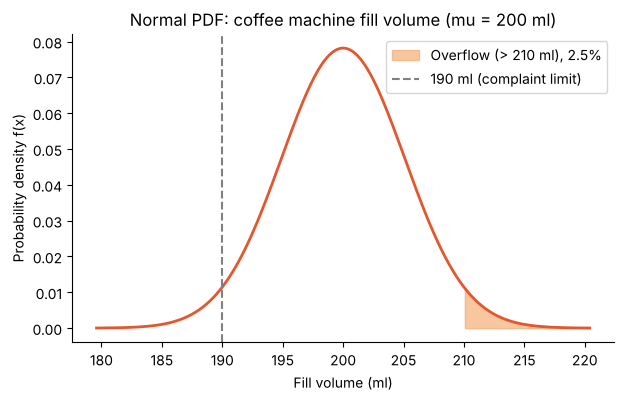

1st percentile = 188.13 ml
P(X > 210)     = 0.0250
P(X < 190)     = 0.0250


In [8]:
mu = 200
z975 = stats.norm.ppf(0.975)          # about 1.95996 (not the rounded 1.96)
sigma = (210 - mu) / z975
print(f"z_0.975 = {z975:.5f}")
print(f"sigma   = {sigma:.4f} ml")

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
y = stats.norm.pdf(x, mu, sigma)

fig, ax = plt.subplots()
ax.plot(x, y, color=CONTINUOUS_COLOR, lw=2)
ax.fill_between(x[x > 210], y[x > 210], color=HIGHLIGHT_COLOR, alpha=0.6, label="Overflow (> 210 ml), 2.5%")
ax.axvline(190, color="gray", ls="--", label="190 ml (complaint limit)")
ax.set_xlabel("Fill volume (ml)")
ax.set_ylabel("Probability density f(x)")
ax.set_title("Normal PDF: coffee machine fill volume (mu = 200 ml)")
ax.legend()
plt.show()

print(f"1st percentile = {stats.norm.ppf(0.01, mu, sigma):.2f} ml")
print(f"P(X > 210)     = {stats.norm.sf(210, mu, sigma):.4f}")
print(f"P(X < 190)     = {stats.norm.cdf(190, mu, sigma):.4f}")

---
# Part E — Uniform distribution
*Recall:* $f(x)=\dfrac{1}{b-a}$ for $a \le x \le b$, $\;P(c \le X \le d)=\dfrac{d-c}{b-a}$, $\;E[X]=\dfrac{a+b}{2}$, $\;Var(X)=\dfrac{(b-a)^2}{12}$.

⚠️ **Note on `scipy`:** for a uniform distribution on $[a, b]$ you must use `loc=a` and `scale=b-a`, **not** `loc=a, scale=b`.

## Q9. Waiting for the campus shuttle &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 🚌 The campus shuttle leaves the gate exactly every **15 minutes**. A student walks up to the stop at a completely random moment, so her waiting time $X$ is uniformly distributed between **0 and 15 minutes**.
>

> **(a)** Find the mean waiting time and the variance, showing the substitution.
> **(b)** Write Python code that:
> - plots the PDF as a flat line/rectangle over $[0, 15]$ in `CONTINUOUS_COLOR` (extend the x-axis a little beyond the range so the flat top is clear),


#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

**(a)** $a = 0,\ b = 15$.
$$E[X] = \frac{a+b}{2} = \frac{0+15}{2} = 7.5 \text{ minutes}$$
$$Var(X) = \frac{(b-a)^2}{12} = \frac{15^2}{12} = \frac{225}{12} = 18.75 \text{ min}^2$$

(PDF height $= \frac{1}{b-a} = \frac{1}{15} \approx 0.0667$.)


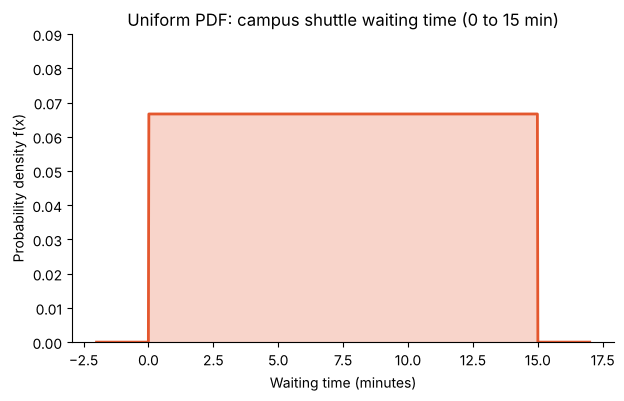

mean = 7.50 min, variance = 18.75 min^2
height of PDF = 0.0667


In [9]:
a, b = 0, 15
x = np.linspace(-2, 17, 1000)
y = stats.uniform.pdf(x, loc=a, scale=b - a)

fig, ax = plt.subplots()
ax.plot(x, y, color=CONTINUOUS_COLOR, lw=2)
ax.fill_between(x, y, color=CONTINUOUS_COLOR, alpha=0.25)
ax.set_ylim(0, 0.09)
ax.set_xlabel("Waiting time (minutes)")
ax.set_ylabel("Probability density f(x)")
ax.set_title("Uniform PDF: campus shuttle waiting time (0 to 15 min)")
plt.show()

print(f"mean = {stats.uniform.mean(a, b - a):.2f} min, variance = {stats.uniform.var(a, b - a):.2f} min^2")
print(f"height of PDF = {1/(b - a):.4f}")